# III. Model and Solving

There is a difference between the description of the 'energy system' what is done **with** oemof and the transfer into a 'numeric model' done **by** oemof.
The Model then is solvable with some solvers. Most known and free to use are CBC and highs. Gurobi is commercial but has an academic license and is much faster.

    1. Energysystem -> 2. Model -> 3. Solve -> 4. Result handling

The energysystem so far...

In [1]:
# copy and paste from former chapter
import oemof.solph as solph

# create energy system
energysystem = solph.EnergySystem(
    timeindex=solph.create_time_index(year=2026,interval=1,number=24)
)

# Create electricity bus
bus_electricity = solph.Bus(
    label="electricity"
)
energysystem.add(bus_electricity)

# PV generation profile (absolute)
pv_profile = [ # Wh/h
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
    0.0, 0.0, 840.3, 2474.1, 3085.95, 3965.4,
    4142.85, 3673.5, 2739.15, 1565.85, 42.3, 0.0,
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0
]

pv_capacity = 1 # -

# Create PV source
pv = solph.components.Source(
    label="pv",
    outputs={
        bus_electricity: solph.Flow(
            nominal_capacity=pv_capacity,
            maximum=pv_profile
        )
    }
)
energysystem.add(pv)

# grid
grid = solph.components.Source(
    label="grid",
    outputs={
        bus_electricity: solph.Flow(
            variable_costs=0.30/1000
        )
    }
)
energysystem.add(grid)

# excess
excess = solph.components.Sink(
    label="excess",
    inputs={
        bus_electricity: solph.Flow()
    }
)
energysystem.add(excess)

# demand electricity
electricity_demand_profile = [ 0.3, 0.25, 0.2, 0.2, 0.25, 0.4, 0.6, 0.7, 0.5, 0.4, 0.35, 0.35, 0.4, 0.4, 0.4, 0.45, 0.6, 0.8, 1.0, 0.9, 0.8, 0.7, 0.5, 0.4 ]
demand_capacity = 4000
electricity_demand = solph.components.Sink(
    label="electricity_demand",
    inputs={
        bus_electricity: solph.Flow(
            nominal_capacity=demand_capacity,
            fix=electricity_demand_profile
        )
    }
)
energysystem.add(electricity_demand)




## Model
- Mathematical decision variables are created for the energy flows.
- The technical properties of the components are translated into mathematical constraints.
- The costs and other objective function terms are combined.
- This results in an optimization problem that can be solved by a solver.
- The model is based on Pyomo and can handle both linear optimization problems (LP) and mixed-integer linear optimization problems (MILP).

In [4]:
model = solph.Model(energysystem)
# here you could pyomo constraints

# more details
print("Amount of model variables: ", model.nvariables())
print("Amount of constraints: ", model.nconstraints())

Amount of model variables:  96
Amount of constraints:  24


## Solve

A solver is a mathematical solution programme. It searches for a combination of energy flows that minimizes the objective function whilst simultaneously satisfying all technical and energy-related constraints.

Solvers differ in particular in terms of computing power, licensing model, installation and the optimization problems they support:

| Solver | License | Characteristics |
|---|---|---|
| HiGHS | Open Source | LP and MILP, powerful and modern |
| CBC | Open Source | LP and MILP, established oemof solver |
| GLPK | Open Source | LP and MILP, more suitable for smaller models |
| Gurobi | Commercial | Very powerful, also offers a free academic license |
| CPLEX | Commercial | Powerful solver for large-scale optimization problems |


Try whatever fits. Since highspy is new to me, I chose that:

In [10]:
# check available solver
from pyomo.opt import SolverFactory

solver_name = "highs" # TODO replace name if wanted

solver = SolverFactory(solver_name)

if not solver.available(exception_flag=False):
    raise RuntimeError(
        "Solver ist nicht verfügbar. "
        f"Bitte {solver_name} installieren."
    )

else:
    print(f"{solver_name} ist verfügbar.")

highs ist verfügbar.


In [11]:
# Start optimization
import logging
import highspy

logging.basicConfig(level=logging.INFO)

print(highspy.Highs().version())

solver_results = model.solve(
    solver=solver_name,
    solve_kwargs={
        "tee": True
    }
)


1.15.1


INFO:pyomo.contrib.appsi.solvers.highs:Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
INFO:pyomo.contrib.appsi.solvers.highs:Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


INFO:pyomo.contrib.appsi.solvers.highs:LP has 24 rows; 96 cols; 72 nonzeros
INFO:pyomo.contrib.appsi.solvers.highs:Coefficient ranges:
INFO:pyomo.contrib.appsi.solvers.highs:  Matrix  [1e+00, 1e+00]
INFO:pyomo.contrib.appsi.solvers.highs:  Cost    [3e-04, 3e-04]
INFO:pyomo.contrib.appsi.solvers.highs:  Bound   [4e+01, 4e+03]
INFO:pyomo.contrib.appsi.solvers.highs:  RHS     [8e+02, 4e+03]
INFO:pyomo.contrib.appsi.solvers.highs:Presolving model
INFO:pyomo.contrib.appsi.solvers.highs:6 rows, 18 cols, 18 nonzeros 0s
INFO:pyomo.contrib.appsi.solvers.highs:0 rows, 0 cols, 0 nonzeros 0s
INFO:pyomo.contrib.appsi.solvers.highs:Presolve reductions: rows 0(-24); columns 0(-96); nonzeros 0(-72) - Reduced to empty
INFO:pyomo.contrib.appsi.solvers.highs:Performed postsolve
INFO:pyomo.contrib.appsi.solvers.highs:Solving the original LP from the solution after postsolve
INFO:pyomo.contrib.appsi.solvers.highs:
INFO:pyomo.contrib.appsi.solvers.highs:Model status        : Optimal
INFO:pyomo.contrib.appsi

LP has 24 rows; 96 cols; 72 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [3e-04, 3e-04]
  Bound   [4e+01, 4e+03]
  RHS     [8e+02, 4e+03]
Presolving model
6 rows, 18 cols, 18 nonzeros 0s
0 rows, 0 cols, 0 nonzeros 0s
Presolve reductions: rows 0(-24); columns 0(-96); nonzeros 0(-72) - Reduced to empty
Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Objective value     :  1.0725465000e+01
P-D objective error :  7.9121748605e-17
HiGHS run time      :          0.01


INFO:root:Optimization successful.


| Status | Bedeutung |
| --- | --- |
| `optimal` | Optimale Lösung gefunden |
| `infeasible` | Modell ist nicht erfüllbar |
| `unbounded` | Zielfunktion ist unbeschränkt |
| `maxTimeLimit` | Zeitlimit erreicht |

## Result Handling

The results are stored in a structured data format and include:
- Energy flows between the individual components.
- Time-dependent power.
- Storage states.
- Other scalar results, such as investment values.

There are various ways to analyse and process results:
- solph.Results is the newest interface and since version 0.6.4 model.solve() returns such an object
- common in older versions: solph.processing.results()
- and some more for specific information...

In [14]:
# common
results = solph.processing.results(model)
print("common: ", results.keys())

# new
print("new: ", solver_results.keys())

common:  dict_keys([("<oemof.solph.buses._bus.Bus: 'electricity'>", "<oemof.solph.components._sink.Sink: 'electricity_demand'>"), ("<oemof.solph.buses._bus.Bus: 'electricity'>", "<oemof.solph.components._sink.Sink: 'excess'>"), ("<oemof.solph.components._source.Source: 'grid'>", "<oemof.solph.buses._bus.Bus: 'electricity'>"), ("<oemof.solph.components._source.Source: 'pv'>", "<oemof.solph.buses._bus.Bus: 'electricity'>")])
new:  {'best_feasible_objective', 'integer_flow', 'positive_gradient', 'negative_gradient', 'objective', 'wallclock_time', 'variable_costs', 'termination_condition', 'best_objective_bound', 'flow'}


common analysis:

In [18]:
import pandas as pd

flow_data = {}

for (source, target), data in results.items():

    if target is None:
        continue

    if "sequences" not in data:
        continue

    sequences = data["sequences"]

    if "flow" in sequences.columns:
        column_name = (
            f"{source.label} -> {target.label}"
        )

        flow_data[column_name] = sequences["flow"]

# DataFrame erstellen

df_flows = pd.DataFrame(flow_data)

display(df_flows.head())

,electricity -> electricity_demand,electricity -> excess,grid -> electricity,pv -> electricity
2026-01-01 00:00:00,1200.0,0.0,1200.0,0.0
2026-01-01 01:00:00,1000.0,0.0,1000.0,0.0
2026-01-01 02:00:00,800.0,0.0,800.0,0.0
2026-01-01 03:00:00,800.0,0.0,800.0,0.0
2026-01-01 04:00:00,1000.0,0.0,1000.0,0.0


new version:

In [ ]:
# new
flow_results = solver_results["flow"]
display(flow_results.head())

and further sequences:

In [ ]:
pv_flow_result = flow_results[(pv,bus_electricity)]
display(pv_flow_result)

visualize common wit plot...

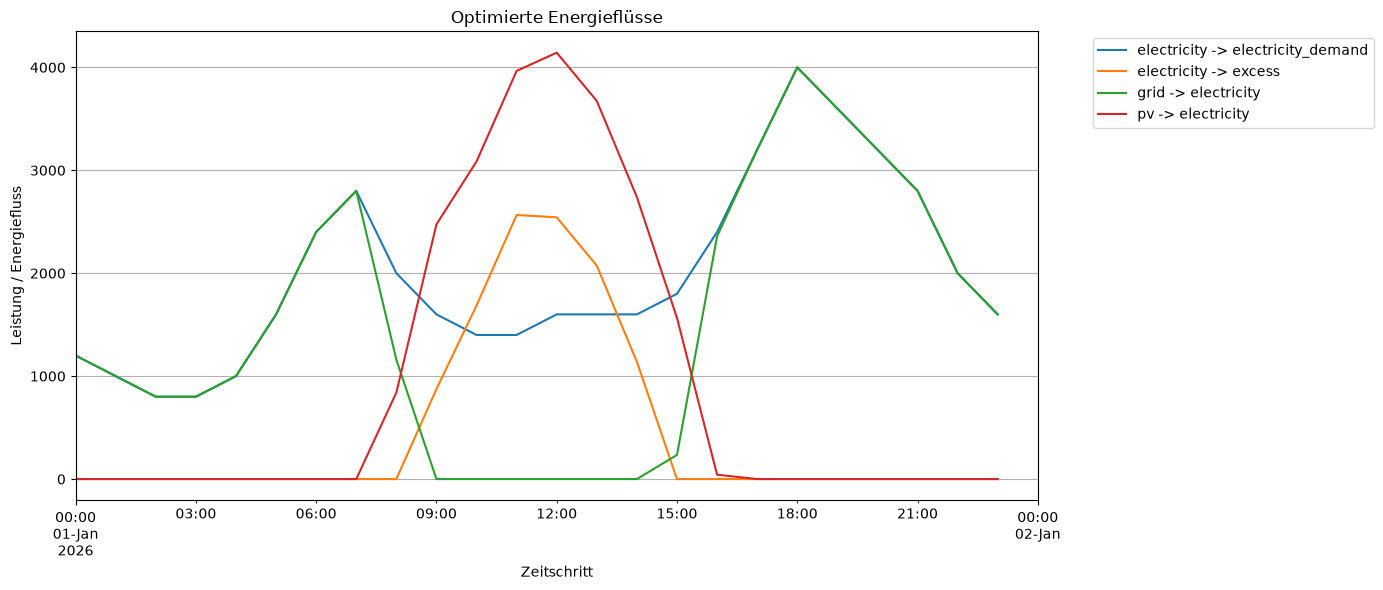

In [26]:
import matplotlib.pyplot as plt

if not df_flows.empty:

    df_flows.plot(
        figsize=(14, 6),
        linewidth=1.5
    )

    plt.title("Optimierte Energieflüsse")
    plt.xlabel("Zeitschritt")
    plt.ylabel("Leistung / Energiefluss")
    plt.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:
    print("Keine Zeitreihen für Energieflüsse gefunden.")